## Task 2

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from scipy.spatial.distance import cdist
import torch
import sklearn
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap.umap_ as umap  
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix
import seaborn as sns


#### 0) Load and Inspect the Datasets

In [45]:
#Load the datasets 2707 digits represented by 16×16 vectors
train_in  = pd.read_csv('train_in.csv',  header=None)   #train 1707 rows, 256 columns
train_out = pd.read_csv('train_out.csv', header=None) 
test_in   = pd.read_csv('test_in.csv',   header=None)  #test 1000 rows, 256 columns
test_out  = pd.read_csv('test_out.csv',  header=None)

#Check the sizes
print(train_in.shape, train_out.shape, test_in.shape, test_out.shape)

#Inspect the dataset
print(train_in.head(10))
print(train_out.head(10))

#Check what data type they are
type(train_in), type(test_out)

(1707, 256) (1707, 1) (1000, 256) (1000, 1)
   0    1    2      3      4      5      6      7      8      9    ...    246  \
0 -1.0 -1.0 -1.0 -1.000 -1.000 -1.000 -1.000 -0.631  0.862 -0.167  ...  0.304   
1 -1.0 -1.0 -1.0 -0.813 -0.671 -0.809 -0.887 -0.671 -0.853 -1.000  ... -0.671   
2 -1.0 -1.0 -1.0 -1.000 -1.000 -1.000 -1.000 -1.000 -1.000 -0.996  ... -1.000   
3 -1.0 -1.0 -1.0 -1.000 -1.000 -0.273  0.684  0.960  0.450 -0.067  ... -0.318   
4 -1.0 -1.0 -1.0 -1.000 -1.000 -0.928 -0.204  0.751  0.466  0.234  ...  0.466   
5 -1.0 -1.0 -1.0 -1.000 -1.000 -0.397  0.983 -0.535 -1.000 -1.000  ...  0.803   
6 -1.0 -1.0 -1.0 -0.830  0.442  1.000  1.000  0.479 -0.328 -0.947  ...  1.000   
7 -1.0 -1.0 -1.0 -1.000 -1.000 -1.000 -1.000  0.510 -0.213 -1.000  ... -0.654   
8 -1.0 -1.0 -1.0 -1.000 -1.000 -0.454  0.879 -0.745 -1.000 -1.000  ...  1.000   
9 -1.0 -1.0 -1.0 -1.000 -1.000 -1.000 -1.000 -0.909  0.801 -0.899  ... -1.000   

     247    248    249    250    251    252    253    254  255  

(pandas.DataFrame, pandas.DataFrame)

**What do our data look like:**

Try to understand what the data represent:
- Each row = one handwritten digit image. (we have 1707 images, each one is a 16x16 image so it contains 256 pixels)
- Each column = one pixel of that image. (A pixel is a vector of numbers. Here each column is a pixel).

We need to assign to each row (image of an handwritten number) the correct label (the actual number it represents).

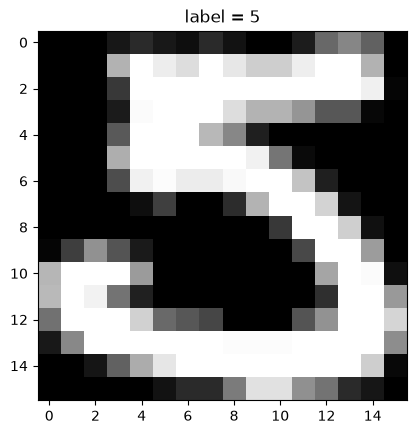

In [46]:
img = train_in.iloc[1].to_numpy().reshape(16, 16) #convert it to array #reshape the row into a 16x16 matrix
plt.imshow(img, cmap='gray')
plt.title(f"label = {train_out.iloc[1, 0]}")
plt.show()

**A point in a 256-dimensional space:**

Picture a normal 2D scatter plot: each point is described by two numbers, (x, y) — a "2-dimensional" point. Now imagine each point needs 256 numbers to be described. That's a point in "256-dimensional space". You can't draw it, but mathematically it's the same idea: each image = one point in that space, with 256 coordinates.

**Understanding what the cloud of points represent:**

In the 256-d dimensional space, there are 1707 points. Each one represents the image of a number:
- C0 = the set of all training rows i where train_out[i] == 0 (the image contains the handwritten number 0). If the training set has, for example, 170 of the "0" images, then C0 is a cloud of 170 points in 256-D space (out of all the points in the 256-D space, there are 170 of them that represent the number 0).
- ...
- C9  = all rows where train_out[i] == 9. Another cloud, of all the rows of train_in that represent an image of the handwritten number 9.

Center of the Cloud:
- Centre C_d of the cloud = the mean over the cloud. 
You will have 10 centers (one for each digit 0,...,9). If you reshape, for example, the center c_3 to 16×16 and plot it, you get a blurry, averaged "3".

**Distances between the clouds:**

Distances between clouds: are the "3" cloud and the "5" cloud close together or far apart? "Close" means the average 3 looks like the average 5. If this happens your classifier will confuse them. "Far" means easy to tell apart.

**Our task:**

The assignment asks:

- For each digit d (0,...,9), compute the center c_d of its cloud C_d.
- Compute the distance between those centers dist[i, j] = ||c_i - c_j||.
Look for the small entries. Those pairs (i, j) have similar-looking average images, so a nearest-mean classifier (which decides "which center am I closest to?") will confuse them.
NB. Train_in contains the rows of 256 pixels that represent the image; Train_out contains the labels of each row-image.

In [ ]:
#Consistent notation

#First, for the further methods it's better to have the datasets as NUMPY ARRAYS so, I'll convert everything
train_X = train_in.to_numpy()
train_Y = train_out.iloc[:, 0].to_numpy()
test_X  = test_in.to_numpy()
test_Y  = test_out.iloc[:, 0].to_numpy()

#Second, most of the methods of this task require standardized features (only input X needs to be scaled)
scaler = StandardScaler().fit(train_X)
train_X_scaled = scaler.transform(train_X)
test_X_scaled  = scaler.transform(test_X)

#Check:
np.mean(train_X_scaled),np.std(train_X_scaled), type(train_X_scaled) #check that it became a numpy array

#So our final datasets will be: train_X_scaled; train_Y; text_X_scaled; test_Y.      

(np.float64(1.6810659484246247e-17), np.float64(1.0), numpy.ndarray)

#### 1) Compute the Centers and the Distances

In [48]:
#For each digit d, (d = 0,1,...,9), let us consider a cloud of points Cd in 256-dimensional space
#For each cloud Cd we can calculate its center, cd, which is just a 256-dimensional vector of means

#Compute the Cloud of points
clouds = {}
for d in range(10):
    clouds[d] = train_X[train_Y == d]

for d in range(10):
    print(d, clouds[d].shape) #just to get an idea of how many rows represent each number

0 (319, 256)
1 (252, 256)
2 (202, 256)
3 (131, 256)
4 (122, 256)
5 (88, 256)
6 (151, 256)
7 (166, 256)
8 (144, 256)
9 (132, 256)


In [49]:
#Compute the centers of the Clouds of Points (mean over the columns, for the rows that represent the same digit)
centers = np.zeros((10, 256))
for d in range(10):
    cloud_d = train_X_scaled[train_Y == d]     # all training images of digit d
    centers[d] = cloud_d.mean(axis=0) 

centers_df = pd.DataFrame(centers)
centers_df.head(10)

,0,1,2,3,4,5,6,7,8,9,...,246,247,248,249,250,251,252,253,254,255
0,-0.068999,-0.117076,-0.152973,-0.157832,-0.137997,0.008203,0.276104,0.187056,0.112177,-0.061350,...,0.642378,0.526401,0.416033,0.494089,0.320248,0.020173,-0.161935,-0.178969,-0.141469,-0.083081
1,-0.068999,-0.133305,-0.202768,-0.307550,-0.447164,-0.619105,-0.442856,0.643090,0.042252,-0.818518,...,-0.835370,0.022880,0.560483,-0.371026,-0.528800,-0.358965,-0.241662,-0.184647,-0.141469,-0.083081
2,0.226921,0.251418,0.270091,0.234491,0.286363,0.326318,0.136973,-0.273858,-0.480364,-0.510377,...,-0.421058,-1.109671,-1.206525,-0.724378,-0.296818,0.082848,0.540420,0.823845,0.823644,0.602338
3,-0.068999,-0.064872,0.111484,0.443253,0.785601,0.903188,0.797343,0.531098,0.563284,0.570742,...,0.699454,0.307122,0.176336,0.454989,0.680261,0.675739,0.464602,0.150361,-0.005628,-0.076076
4,-0.068999,-0.133305,-0.202768,-0.263302,-0.269609,-0.392582,-0.797418,-1.152555,-1.044055,-0.585427,...,-0.851521,-0.990532,-0.612946,0.070309,0.153673,0.201958,0.011014,-0.093467,-0.074004,-0.083081
5,-0.068999,-0.099571,-0.129582,-0.119048,-0.131242,-0.264235,-0.389848,-0.625989,-0.438523,0.194133,...,0.410125,0.126410,0.127002,0.573564,0.829182,0.780938,0.502633,0.235289,0.040934,-0.055272
6,-0.068999,-0.133305,-0.202768,-0.307550,-0.442018,-0.566402,-0.739041,-0.737507,-0.072852,0.294585,...,0.752516,0.434815,0.159562,0.187906,0.075379,-0.030672,-0.110869,-0.153380,-0.141469,-0.083081
7,0.266524,0.518893,0.651052,0.746154,0.673907,0.529373,0.183726,-0.271961,-0.118726,0.426304,...,-0.149889,-0.056677,-0.483814,-0.652831,-0.485920,-0.352608,-0.241662,-0.184647,-0.141469,-0.083081
8,-0.052967,0.036576,0.112381,0.184896,0.311421,0.530436,0.717180,0.481381,0.390860,0.286997,...,0.332286,0.512519,0.598477,0.606608,0.248023,-0.043181,-0.146731,-0.154601,-0.141378,-0.083081
9,-0.068999,-0.133305,-0.202768,-0.295680,-0.375603,-0.291065,0.006185,0.355339,0.887890,1.150971,...,-0.528659,-0.076501,-0.149214,-0.331832,-0.425830,-0.342515,-0.189855,-0.119091,-0.107803,-0.083081


In [50]:
#Compute the distances between the centers of the 10 clouds, dist_ij = dist(ci,cj), for i,j = 0,1,...,9.
dist = cdist(centers, centers)
dist_df = pd.DataFrame(dist, index=range(10), columns=range(10))
print(dist_df.round(1))

      0     1     2     3     4     5     6     7     8     9
0   0.0  18.3  13.3  12.4  13.9  10.8  11.1  15.9  13.3  14.9
1  18.3   0.0  13.8  14.6  12.7  14.3  12.9  13.8  12.3  12.0
2  13.3  13.8   0.0  11.0  11.6  11.3  10.4  13.0  10.4  12.6
3  12.4  14.6  11.0   0.0  11.8   8.4  11.7  11.8   9.1  10.7
4  13.9  12.7  11.6  11.8   0.0  10.4  11.1  10.2   9.5   7.8
5  10.8  14.3  11.3   8.4  10.4   0.0   9.3  11.8   9.6  10.8
6  11.1  12.9  10.4  11.7  11.1   9.3   0.0  14.2  10.7  12.8
7  15.9  13.8  13.0  11.8  10.2  11.8  14.2   0.0  11.0   7.7
8  13.3  12.3  10.4   9.1   9.5   9.6  10.7  11.0   0.0   8.0
9  14.9  12.0  12.6  10.7   7.8  10.8  12.8   7.7   8.0   0.0


In [51]:
#Quick way to find the minimum distance in each column (excluding the diagonal)
dist_no_diag = dist.copy()
np.fill_diagonal(dist_no_diag, np.inf)
min_dist = dist_no_diag.min(axis=1)
print(min_dist)

[10.80673063 12.01249929 10.3979102   8.35746857  7.78408571  8.35746857
  9.26792755  7.65126914  8.04588257  7.65126914]


**Q1:** *Given all these distances, try to say something about the expected accuracy of your classifier. What pairs of digits seem to be most difficult to separate?*

Given the distance matrix, the digits that seem to be most difficult to separate are: 3 and 5; 9 and 4; 7 and 9.  


#### 2) Experiment with three dimensionality reduction algorithms: PCA, U-MAP, and t-SNE

NB. Remember: PCA, t-SNE and UMAP are unsupervised techniques, so they look only at the 256 pixel values of each image and try to find structure. Therefore, we need to use train_in.

**PCA**

In [ ]:
#PCA
pca_ = PCA(n_components=2)
pca_train_X = pca_.fit_transform(train_X_scaled)

#Transform it back into df to visualise the PCs
pca_train_X_df = pd.DataFrame(data = pca_train_X
                               , columns = ['PC 1', 'PC 2'])
pca_train_X_df.tail()


,PC 1,PC 2
1702,-4.637668,-1.913452
1703,-5.940151,0.046786
1704,-5.177932,5.262797
1705,-5.229628,0.895805
1706,-1.558550,4.051693


<Figure size 640x480 with 0 Axes>

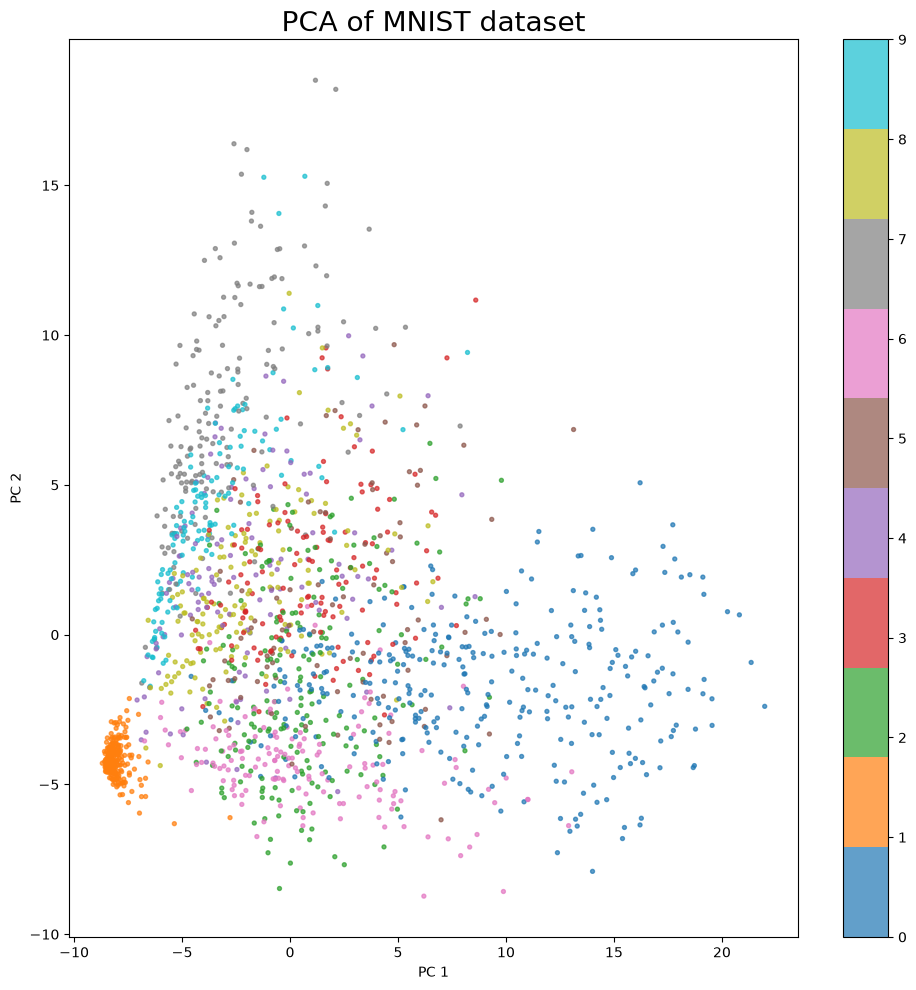

In [53]:
#Plot the 2 PCs
plt.figure()
plt.figure(figsize=(10,10))
scatter = plt.scatter(pca_train_X[:,0], pca_train_X[:,1], c=train_Y, cmap='tab10', s=8, alpha=0.7)
plt.colorbar(scatter, ticks=range(10))
plt.title("PCA of MNIST dataset",fontsize=20)
plt.xlabel("PC 1"); 
plt.ylabel("PC 2")
plt.tight_layout()
plt.show()

**U-MAP**

In [54]:
#U-MAP
reducer = umap.UMAP(n_components=2)
umap_train_X = reducer.fit_transform(train_X_scaled)

<Figure size 640x480 with 0 Axes>

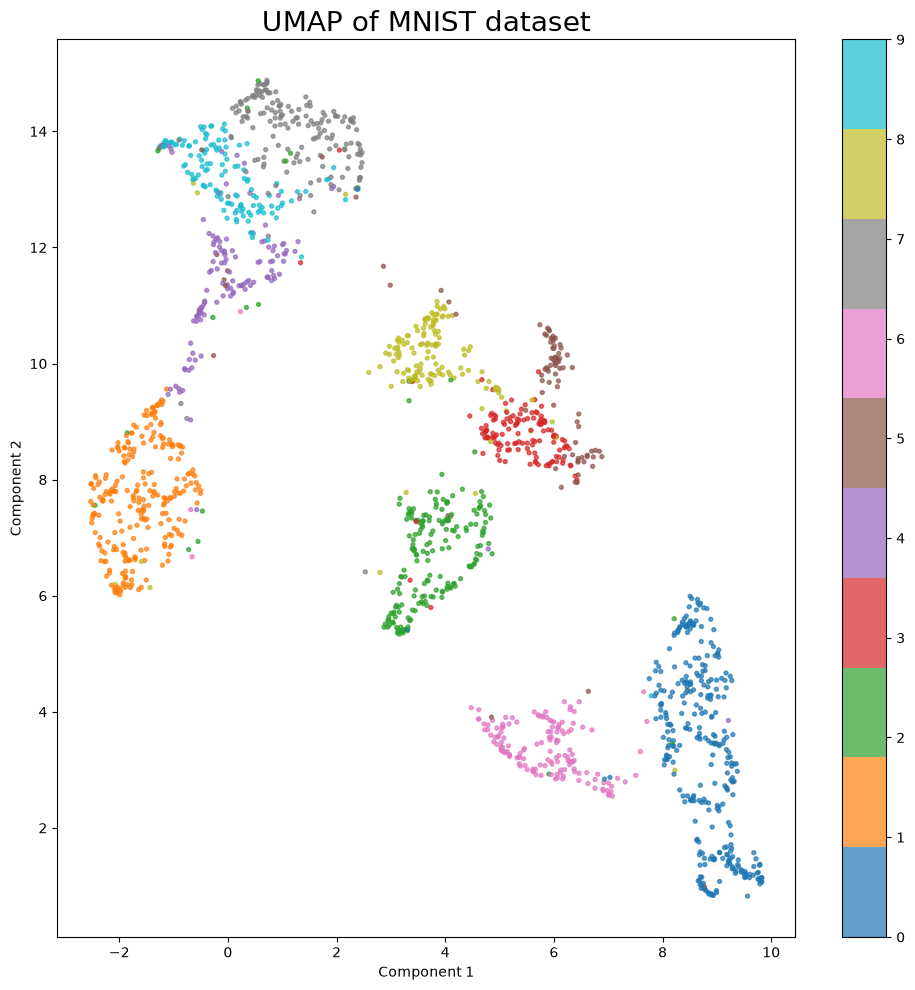

In [55]:
#Plot UMAP

plt.figure()
plt.figure(figsize=(10,10))
scatter = plt.scatter(umap_train_X[:,0], umap_train_X[:,1], c=train_Y, cmap='tab10', s=8, alpha=0.7)
plt.colorbar(scatter, ticks=range(10))
plt.title("UMAP of MNIST dataset",fontsize=20)
plt.xlabel("Component 1"); 
plt.ylabel("Component 2")
plt.tight_layout()
plt.show()

**t-SNE**

In [56]:
#t-SNE

tsne = TSNE(n_components=2, perplexity=30, random_state=0, init='pca')
tsne_train_X = tsne.fit_transform(train_X_scaled)

<Figure size 640x480 with 0 Axes>

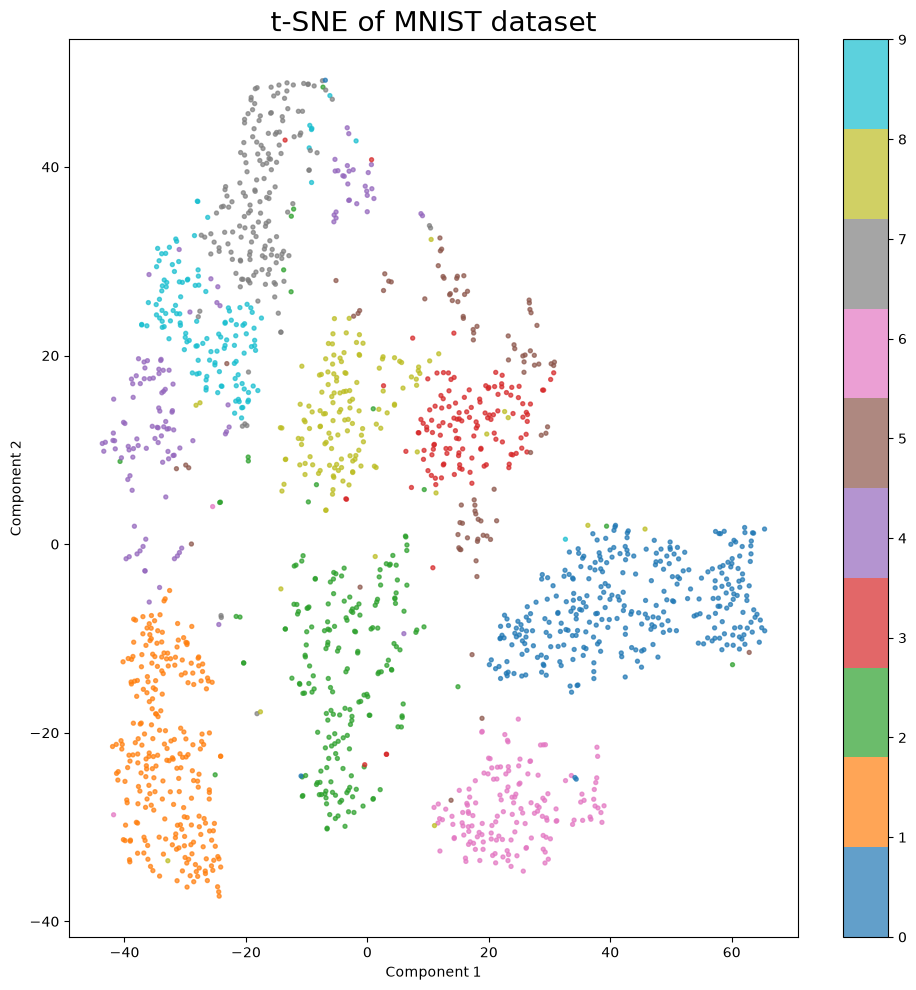

In [57]:
#Plot t-SNE

plt.figure()
plt.figure(figsize=(10,10))
scatter = plt.scatter(tsne_train_X[:,0], tsne_train_X[:,1], c=train_Y, cmap='tab10', s=8, alpha=0.7)
plt.colorbar(scatter, ticks=range(10))
plt.title("t-SNE of MNIST dataset",fontsize=20)
plt.xlabel("Component 1"); 
plt.ylabel("Component 2")
plt.tight_layout()
plt.show()

*Does the visualization agree with your intuitions and the between-class distance matrix?*

- From the distance matrix the closest digits were: 3,4,5,7,9.
- From PCA the most overlapping digits are: all of them, the only separable ones seem to be 0 and 1.
- From U-MAP the most overlapping digits are: 3,4,5,7,8,9.
- From t-SNE the most overlapping digits are: 3,4,5,7,9.

So yes, the visualizations agree with what was seen in the distance matrix.

#### 3) Nearest Mean Classifier

In [58]:
#predictions
nmc_pred_train = np.argmin(cdist(train_X_scaled, centers), axis=1)
nmc_pred_test = np.argmin(cdist(test_X_scaled, centers), axis=1)

#accuracies
nmc_acc_train = (nmc_pred_train == train_Y).mean()
nmc_acc_test  = (nmc_pred_test  == test_Y).mean() 
print("Accuracy nmc train:", round(nmc_acc_train, 3), "\nAccuracy nmc test:", round(nmc_acc_test, 3))

Accuracy nmc train: 0.844 
Accuracy nmc test: 0.798


#### 4) KNN

In [ ]:
#Before fitting KNN, we need to find the optimal k, we will use accuracies to make this decision

for k in [1,2,3,4,5,6,7,8,9]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(train_X_scaled, train_Y)
    acc_tr = knn.score(train_X_scaled, train_Y)
    acc_te = knn.score(test_X_scaled,  test_Y)
    print(f"k={k}: train={acc_tr:.4f}  test={acc_te:.4f}")

k=1: train=1.0000  test=0.9070
k=2: train=0.9701  test=0.8940
k=3: train=0.9695  test=0.9050
k=4: train=0.9590  test=0.8980
k=5: train=0.9590  test=0.9060
k=6: train=0.9555  test=0.9000
k=7: train=0.9438  test=0.8930
k=8: train=0.9402  test=0.8900
k=9: train=0.9420  test=0.8870


In [60]:
#KNN
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(train_X_scaled, train_Y)

#predictions
knn_pred_train = knn.predict(train_X_scaled)
knn_pred_test  = knn.predict(test_X_scaled)

#accuracies
knn_acc_train = knn.score(train_X_scaled, train_Y)
knn_acc_test = knn.score(test_X_scaled, test_Y)
print("Accuracy knn train:", round(knn_acc_train, 3), "\nAccuracy knn test:", round(knn_acc_test, 3))

Accuracy knn train: 0.97 
Accuracy knn test: 0.905


Now the confusion matrices for nmc and knn:

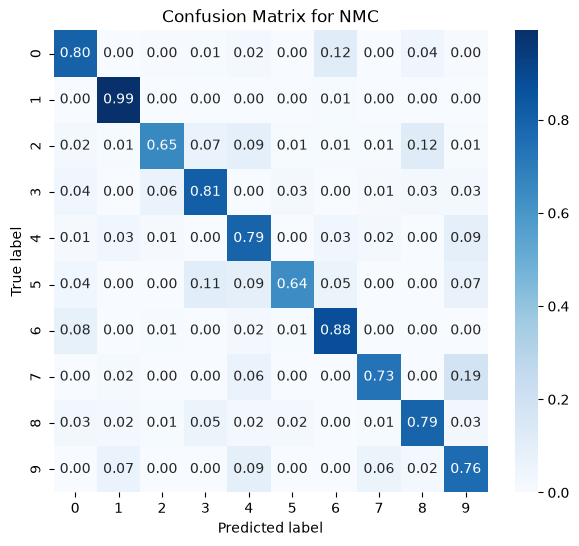

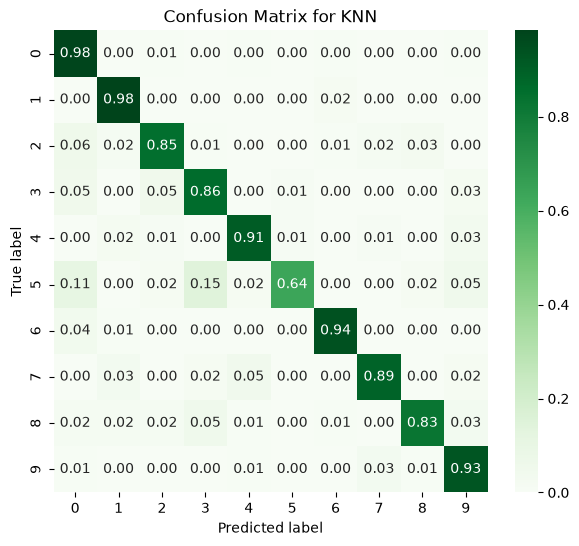

In [ ]:
#Confusion matrices for nmc and knn:
CM_nmc = confusion_matrix(test_Y, nmc_pred_test, normalize='true')
CM_knn = confusion_matrix(test_Y, knn_pred_test, normalize='true')
#NB. We have to normalise the counts, because as we have seen when we plotted the clouds dictionary, 
# not all the digits have the same number of test samples, so the raw counts are not very informative.  

#Visual representation of the confusion matricx for nmc
plt.figure(figsize=(7, 6))
sns.heatmap(CM_nmc, annot=True, fmt='.2f', cmap='Blues')
plt.title('Confusion Matrix for NMC')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

#Visual representation of the confusion matricx for knn
plt.figure(figsize=(7, 6))
sns.heatmap(CM_knn, annot=True, fmt='.2f', cmap='Greens')
plt.title('Confusion Matrix for KNN')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()


*Which digits are most difficult to classify correctly?*

The digits with the lowest classification accuracy are: 
- According to NMC: 2 and 5 (acc = 0.65); 7 and 9 (acc = 0.75)
- According to KNN: 5 

There are two interesting aspects here: 
- First of all, KNN performed much better than NMC on both train and test set. For this reason it's not surprising to see lower per-class accuracies in the confusion matrix. 
- Secondly, we look at which numbers appear to be "hard to classify" according to these two methods. KNN has a quite low accuracy only for the digit "5" which is coherent with what was observed in the previous methods. On the other hand, NMC shows a low accuracy for numbers 2,5,7,9. The digits "5", "7", and "9" were hard to classify also for some of the previous models, but the digit "2" appeared quite distinguishable from the t-SNE and U-MAP representations. 

The NMC method had a quite low accuracy on both the train (acc = 0.844) and test (acc = 0.798) set, so it is possible that this mismatch between the results of the models is due to the fact that some models are more suited for this Task than others. 

Anyways, to sum it up, the hardest digits to classify appeared to be: 3,5,7,9.